# 05 — PCA-based Dimensionality Reduction
**Member 5.** Transform the 30 standardised features into a smaller number of
principal components and test whether classifiers keep their performance.

* Settings: **2, 5, 10 components** and the number that keeps **≈95 % of the
  training variance**, compared with the same model on all 30 original features.
* Classifiers: Logistic Regression, KNN and SVM (as in the proposal), plus
  Gaussian NB, which is interesting here because PCA components are uncorrelated,
  matching NB's independence assumption.
* Following the coordination plan, classifiers reuse the hyper-parameters tuned by
  Members 2–3 (`results/best_params.json`). A re-tuning sanity check is included at the end.
* `StandardScaler → PCA → classifier` lives in one `Pipeline`, so PCA is re-fitted
  on each CV training fold only. The test set is not used here.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from common import *
from models import build_pipeline, display_name, GRIDS

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160, "display.max_columns", 40)
X_train, X_test, y_train, y_test = get_split()
del X_test, y_test
PARAMS = load_best_params()
CLASSIFIERS = ["logreg", "knn", "svm", "gnb"]

## 1. Explained variance (training set)

In [2]:
Z = StandardScaler().fit_transform(X_train)
pca_full = PCA().fit(Z)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
n95 = int(np.searchsorted(cum, 0.95) + 1)
print(f"components needed for 95% variance: {n95}")
pd.DataFrame({"PC": range(1, 16), "explained_var": evr[:15], "cumulative": cum[:15]}).round(4)

components needed for 95% variance: 10


,PC,explained_var,cumulative
0,1,0.4459,0.4459
1,2,0.1855,0.6314
2,3,0.0958,0.7272
3,4,0.0659,0.7932
4,5,0.0562,0.8494
5,6,0.0399,0.8893
6,7,0.0221,0.9114
7,8,0.0161,0.9276
8,9,0.0128,0.9404
9,10,0.0117,0.9521


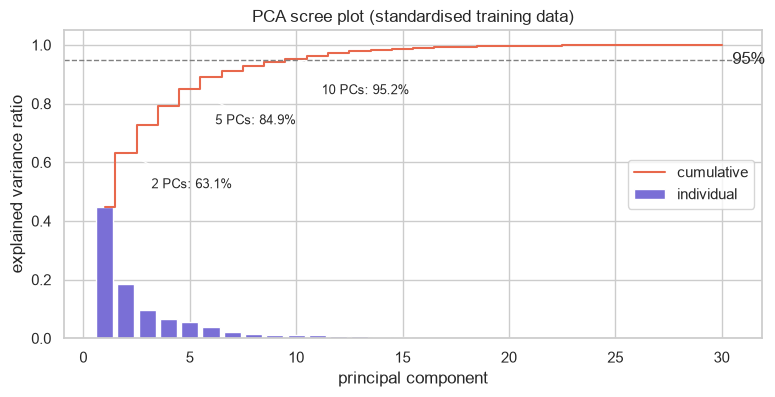

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(1, 31), evr, color="#7A6FD6", label="individual")
ax.step(range(1, 31), cum, where="mid", color="#E8684C", label="cumulative")
for t in [0.95]:
    ax.axhline(t, ls="--", color="grey", lw=1); ax.text(30.5, t, f"{t:.0%}", va="center")
for k in [2, 5, 10]:
    ax.annotate(f"{k} PCs: {cum[k-1]:.1%}", (k, cum[k-1]), xytext=(k + 1.2, cum[k-1] - 0.12),
                arrowprops=dict(arrowstyle="->", lw=.8), fontsize=9)
ax.set_xlabel("principal component"); ax.set_ylabel("explained variance ratio"); ax.legend(loc="center right")
ax.set_title("PCA scree plot (standardised training data)")
savefig(fig, "05_scree"); plt.show()

Variance is concentrated in the first few components: PC1 alone explains about 44 %
and PC1–PC2 about 63 %. Ten components keep ≈95 %. This confirms how
redundant the 30 features are.

## 2. What do the components mean?

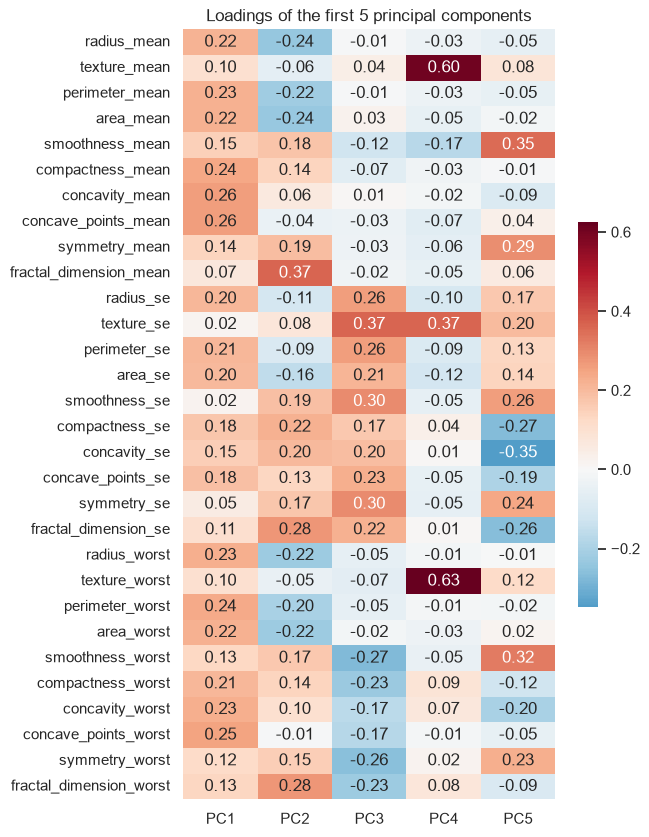

In [4]:
load = pd.DataFrame(pca_full.components_[:5].T, index=FEATURE_NAMES, columns=[f"PC{i}" for i in range(1, 6)])
fig, ax = plt.subplots(figsize=(6, 10))
sns.heatmap(load, cmap="RdBu_r", center=0, annot=True, fmt=".2f", ax=ax, cbar_kws={"shrink": .5})
ax.set_title("Loadings of the first 5 principal components")
savefig(fig, "05_loadings"); plt.show()

In [5]:
for pc in ["PC1", "PC2"]:
    s = load[pc].abs().sort_values(ascending=False)
    print(pc, "top loadings:", ", ".join(f"{f} ({load.loc[f, pc]:+.2f})" for f in s.index[:6]))

PC1 top loadings: concave_points_mean (+0.26), concavity_mean (+0.26), concave_points_worst (+0.25), compactness_mean (+0.24), perimeter_worst (+0.24), radius_worst (+0.23)
PC2 top loadings: fractal_dimension_mean (+0.37), fractal_dimension_worst (+0.28), fractal_dimension_se (+0.28), radius_mean (-0.24), area_mean (-0.24), compactness_se (+0.22)


* **PC1** loads positively on almost every feature, most strongly concavity, concave
  points, compactness and size. It is an overall "large and irregular nucleus" axis.
* **PC2** contrasts size (negative radius/area loadings) with fractal dimension,
  smoothness and the `_se` shape features. Roughly, it captures "small but finely irregular".

Each component mixes all 30 original measurements, so a model built on PCs is much harder
to explain in clinical terms than one built on selected features (notebook 06).

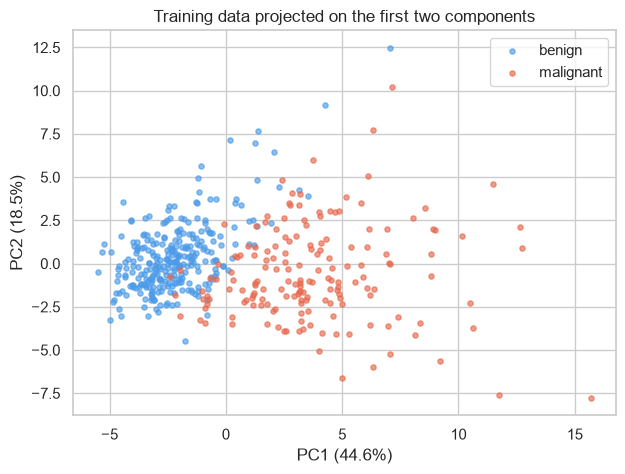

In [6]:
pcs = PCA(n_components=2).fit_transform(Z)
fig, ax = plt.subplots(figsize=(7, 5))
for lab, col in [(0, "#4C9BE8"), (1, "#E8684C")]:
    m = y_train.values == lab
    ax.scatter(pcs[m, 0], pcs[m, 1], s=14, alpha=.65, c=col, label=CLASS_NAMES[lab])
ax.set_xlabel(f"PC1 ({evr[0]:.1%})"); ax.set_ylabel(f"PC2 ({evr[1]:.1%})"); ax.legend()
ax.set_title("Training data projected on the first two components")
savefig(fig, "05_pc1_pc2_scatter"); plt.show()

Even in 2-D the classes are almost linearly separable along PC1. PCA is
*unsupervised*: it was not told the labels, yet the direction of maximum variance
happens to be the direction that separates benign from malignant.

## 3. Main experiment: 2 / 5 / 10 / 95 % components vs all 30 features

In [7]:
settings = [("all 30 (no PCA)", None), ("PCA 2", 2), ("PCA 5", 5), ("PCA 10", 10), ("PCA 95% var", 0.95)]
rows = []
for key in CLASSIFIERS:
    for label, n in settings:
        reducer = None if n is None else PCA(n_components=n, random_state=RANDOM_STATE)
        pipe = build_pipeline(key, PARAMS[key], reducer=reducer)
        n_feat = 30 if n is None else (n95 if n == 0.95 else n)
        rows.append(cv_evaluate(pipe, X_train, y_train, name=display_name(key), key=key,
                                method="none" if n is None else "PCA", setting=label,
                                n_components=str(n), n_features=n_feat))
pca_df = pd.DataFrame(rows)
save_rows(rows, "cv_05_pca.csv")
summarize(rows)[["model", "setting", "n_features", "accuracy", "recall", "specificity", "f1", "roc_auc"]]

,model,setting,n_features,accuracy,recall,specificity,f1,roc_auc
0,Logistic Regression,all 30 (no PCA),30,0.9758 ± 0.0082,0.9588 ± 0.0144,0.9860 ± 0.0131,0.9674 ± 0.0109,0.9949 ± 0.0056
1,Logistic Regression,PCA 2,2,0.9538 ± 0.0108,0.9471 ± 0.0220,0.9579 ± 0.0179,0.9388 ± 0.0137,0.9870 ± 0.0073
2,Logistic Regression,PCA 5,5,0.9714 ± 0.0088,0.9647 ± 0.0118,0.9754 ± 0.0086,0.9619 ± 0.0117,0.9939 ± 0.0060
3,Logistic Regression,PCA 10,10,0.9758 ± 0.0082,0.9647 ± 0.0118,0.9825 ± 0.0157,0.9677 ± 0.0106,0.9943 ± 0.0058
4,Logistic Regression,PCA 95% var,10,0.9758 ± 0.0082,0.9647 ± 0.0118,0.9825 ± 0.0157,0.9677 ± 0.0106,0.9943 ± 0.0058
5,KNN,all 30 (no PCA),30,0.9758 ± 0.0162,0.9471 ± 0.0343,0.9930 ± 0.0086,0.9667 ± 0.0223,0.9834 ± 0.0102
6,KNN,PCA 2,2,0.9231 ± 0.0184,0.8765 ± 0.0343,0.9509 ± 0.0131,0.8947 ± 0.0255,0.9527 ± 0.0281
7,KNN,PCA 5,5,0.9626 ± 0.0179,0.9353 ± 0.0220,0.9789 ± 0.0172,0.9493 ± 0.0239,0.9769 ± 0.0098
8,KNN,PCA 10,10,0.9626 ± 0.0179,0.9235 ± 0.0300,0.9860 ± 0.0131,0.9485 ± 0.0247,0.9843 ± 0.0118
9,KNN,PCA 95% var,10,0.9626 ± 0.0179,0.9235 ± 0.0300,0.9860 ± 0.0131,0.9485 ± 0.0247,0.9843 ± 0.0118


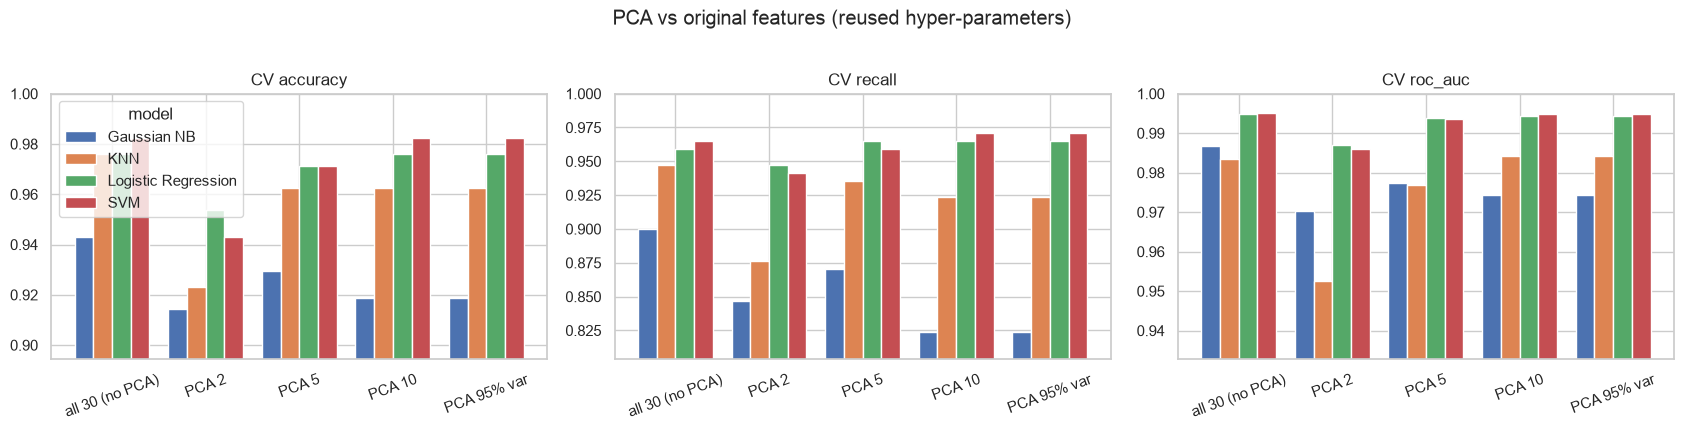

In [8]:
order = [s for s, _ in settings]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), sharey=False)
for ax, m in zip(axes, ["accuracy", "recall", "roc_auc"]):
    piv = pca_df.pivot(index="setting", columns="model", values=f"cv_{m}").loc[order]
    piv.plot(kind="bar", ax=ax, width=.8, rot=20, legend=ax is axes[0])
    lo = max(0.8, piv.values.min() - 0.02); ax.set_ylim(lo, 1.0)
    ax.set_title(f"CV {m}"); ax.set_xlabel("")
fig.suptitle("PCA vs original features (reused hyper-parameters)", y=1.02); fig.tight_layout()
savefig(fig, "05_pca_settings"); plt.show()

## 4. Performance as a function of the number of components

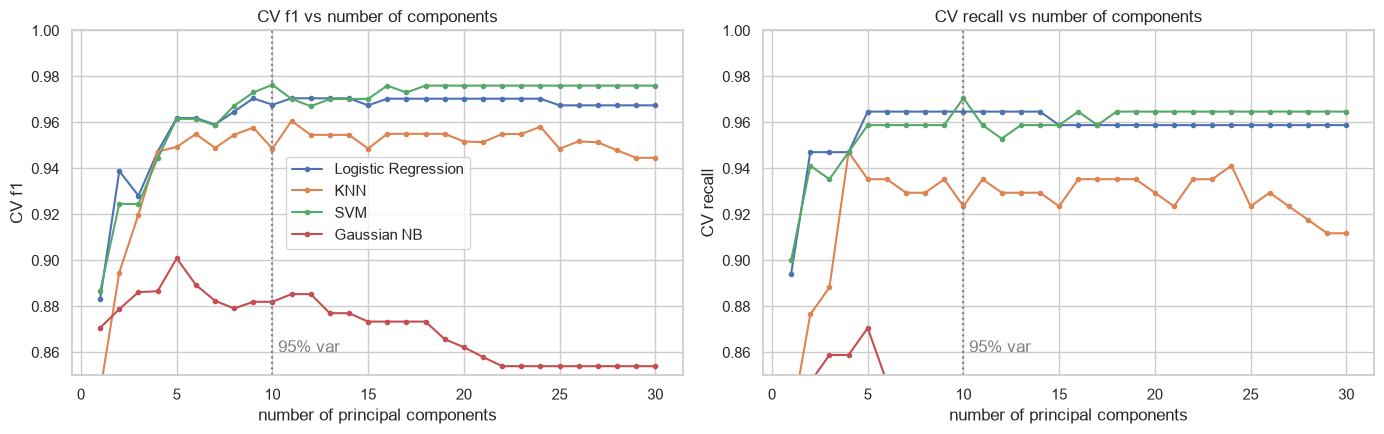

In [9]:
curve = []
for key in CLASSIFIERS:
    for n in range(1, 31):
        pipe = build_pipeline(key, PARAMS[key], reducer=PCA(n_components=n, random_state=RANDOM_STATE))
        curve.append(cv_evaluate(pipe, X_train, y_train, name=display_name(key), key=key, n_features=n))
curve = pd.DataFrame(curve)
curve.to_csv(RESULTS_DIR / "cv_05_pca_curve.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
for ax, m in zip(axes, ["f1", "recall"]):
    for key, g in curve.groupby("key", sort=False):
        ax.plot(g["n_features"], g[f"cv_{m}"], "o-", ms=3, label=display_name(key))
    ax.axvline(n95, ls=":", color="grey"); ax.text(n95 + .3, 0.86, "95% var", color="grey")
    ax.set_ylim(0.85, 1.0); ax.set_xlabel("number of principal components"); ax.set_ylabel(f"CV {m}")
    ax.set_title(f"CV {m} vs number of components")
axes[0].legend(); fig.tight_layout(); savefig(fig, "05_pca_curve"); plt.show()

In [10]:
best_n = curve.loc[curve.groupby("key")["cv_f1"].idxmax(), ["model", "n_features", "cv_f1", "cv_recall", "cv_accuracy"]]
full = pca_df[pca_df.method == "none"].set_index("model")[["cv_f1", "cv_recall", "cv_accuracy"]].add_suffix("_all30")
best_n.set_index("model").join(full).round(4)

,n_features,cv_f1,cv_recall,cv_accuracy,cv_f1_all30,cv_recall_all30,cv_accuracy_all30
model,,,,,,,
Gaussian NB,5,0.9009,0.8706,0.9297,0.9214,0.9000,0.9429
KNN,11,0.9607,0.9353,0.9714,0.9667,0.9471,0.9758
Logistic Regression,11,0.9705,0.9647,0.9780,0.9674,0.9588,0.9758
SVM,10,0.9764,0.9706,0.9824,0.9760,0.9647,0.9824


In [11]:
# smallest number of components within 1 F1-point (0.01) of the same model on all 30 features
small = []
for key, g in curve.groupby("key", sort=False):
    ref = pca_df[(pca_df.key == key) & (pca_df.method == "none")]["cv_f1"].iloc[0]
    ok = g[g["cv_f1"] >= ref - 0.01]
    small.append({"model": display_name(key), "all30_f1": ref,
                  "min_components_within_0.01": int(ok["n_features"].min()) if len(ok) else None})
pd.DataFrame(small).round(4)

,model,all30_f1,min_components_within_0.01
0,Logistic Regression,0.9674,5.0
1,KNN,0.9667,9.0
2,SVM,0.9760,8.0
3,Gaussian NB,0.9214,NaN


## 5. Sanity check: re-tuning the classifiers on PCA features
Reusing hyper-parameters tuned on 30 features could handicap PCA (e.g. a KNN
neighbourhood size or RBF `gamma` chosen for 30-D may not suit 5-D). Here each
classifier is re-tuned, with the same grids as Members 2–3, inside each PCA setting.

In [12]:
retuned = []
for key in CLASSIFIERS:
    for label, n in settings[1:]:
        gs = tune(build_pipeline(key, reducer=PCA(n_components=n, random_state=RANDOM_STATE)), GRIDS[key],
                  X_train, y_train)
        row = best_cv_row(gs, display_name(key), key=key, setting=label)
        row["reused_f1"] = pca_df[(pca_df.key == key) & (pca_df.setting == label)]["cv_f1"].iloc[0]
        retuned.append(row)
rt = pd.DataFrame(retuned)
rt["gain_from_retuning"] = rt["cv_f1"] - rt["reused_f1"]
rt.to_csv(RESULTS_DIR / "cv_05_pca_retuned.csv", index=False)
rt[["model", "setting", "reused_f1", "cv_f1", "gain_from_retuning", "cv_recall"]].round(4)

,model,setting,reused_f1,cv_f1,gain_from_retuning,cv_recall
0,Logistic Regression,PCA 2,0.9388,0.9388,0.0000,0.9471
1,Logistic Regression,PCA 5,0.9619,0.9649,0.0030,0.9706
2,Logistic Regression,PCA 10,0.9677,0.9707,0.0030,0.9706
3,Logistic Regression,PCA 95% var,0.9677,0.9707,0.0030,0.9706
4,KNN,PCA 2,0.8947,0.9255,0.0308,0.9176
5,KNN,PCA 5,0.9493,0.9668,0.0175,0.9471
6,KNN,PCA 10,0.9485,0.9605,0.0119,0.9353
7,KNN,PCA 95% var,0.9485,0.9605,0.0119,0.9353
8,SVM,PCA 2,0.9246,0.9281,0.0035,0.9471
9,SVM,PCA 5,0.9615,0.9647,0.0032,0.9647
